# 7-loyiha
TensorFlow va Keras yordamida tasvirlarni tasniflash

Standart demo: sun’iy tomografik fantomlar, haqiqiy rentgen/MRI emas. Haqiqiy PNG/JPG tasvirlar data/manifest.csv orqali ulanadi. patient_id, path, label (0 yoki 1) ustunlari majburiy.


In [1]:
# TensorFlow va Keras yordamida tasvirlarni tasniflash
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    brier_score_loss, ConfusionMatrixDisplay)

def binary_metrics(y, probability, threshold=0.5):
    pred = np.asarray(probability) >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=int(len(y)), threshold=float(threshold),
        accuracy=float(accuracy_score(y, pred)),
        precision=float(precision_score(y, pred, zero_division=0)),
        recall=float(recall_score(y, pred, zero_division=0)),
        specificity=float(tn / (tn + fp)) if tn + fp else None,
        f1=float(f1_score(y, pred, zero_division=0)),
        roc_auc=float(roc_auc_score(y, probability))
            if len(np.unique(y)) == 2 else None,
        brier=float(brier_score_loss(y, probability)),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

def make_demo():
    rng = np.random.default_rng(SEED)
    folder = DATA / "synthetic_images"
    folder.mkdir(exist_ok=True)
    yy, xx = np.mgrid[-1:1:32j, -1:1:32j]
    rows = []
    for patient in range(100):
        label = patient % 2
        for view in range(2):
            body = ((xx / 0.8)**2 + (yy / 0.95)**2 < 1) * 0.35
            body += np.exp(-((xx + .3)**2 + yy**2) / .1) * .25
            if label:
                cx, cy = rng.uniform(-.25, .25, 2)
                body += ((xx - cx)**2 + (yy - cy)**2 < .05) * .6
            image = np.clip(body + rng.normal(0, .025, body.shape), 0, 1)
            rel = f"synthetic_images/p{patient:03d}_{view}.png"
            Image.fromarray((image * 255).astype("uint8")).save(DATA / rel)
            rows.append({"patient_id": f"SYN{patient:03d}",
                         "path": rel, "label": label})
    pd.DataFrame(rows).to_csv(DATA / "manifest.csv", index=False)
    (DATA / "DATA_SOURCE.txt").write_text(
        "SYNTHETIC PHANTOM. 1 = artificial marker, 0 = no marker.\n"
        "Haqiqiy kasallik yoki klinik tasvir emas.\n", encoding="utf-8")

def main():
    tf.keras.utils.set_random_seed(SEED)
    manifest = DATA / "manifest.csv"
    if not manifest.exists():
        make_demo()
    df = pd.read_csv(manifest)
    required = {"patient_id", "path", "label"}
    if not required.issubset(df) or df[list(required)].isna().any().any():
        raise ValueError("Manifest ustunlari yoki qiymatlari noto‘g‘ri")
    if not set(df.label.unique()).issubset({0, 1}):
        raise ValueError("Faqat 0 va 1 label qo‘llanadi")
    if df.groupby("patient_id").label.nunique().max() != 1:
        raise ValueError("Bitta bemorda qarama-qarshi label bor")
    patients = df.groupby("patient_id").label.first()
    train_ids, hold = train_test_split(patients.index, test_size=.4,
        stratify=patients, random_state=SEED)
    val_ids, test_ids = train_test_split(hold, test_size=.5,
        stratify=patients.loc[hold], random_state=SEED)
    assert not set(train_ids) & set(test_ids)
    assert not set(val_ids) & set(test_ids)
    def load(ids):
        sub = df[df.patient_id.isin(ids)].copy()
        images = []
        for path in sub.path:
            with Image.open(DATA / path) as image:
                images.append(np.asarray(image.convert("L").resize(
                    (32, 32)), dtype="float32") / 255.0)
        return np.stack(images)[..., None], sub.label.to_numpy(), sub
    Xtr, ytr, _ = load(train_ids)
    Xv, yv, _ = load(val_ids)
    Xt, yt, test_rows = load(test_ids)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    tr = tf.data.Dataset.from_tensor_slices((Xtr, ytr))
    tr = tr.shuffle(len(ytr), seed=SEED).batch(16).with_options(options)
    va = tf.data.Dataset.from_tensor_slices((Xv, yv))
    va = va.batch(16).with_options(options)
    model = tf.keras.Sequential([
        tf.keras.layers.Input((32, 32, 1)),
        tf.keras.layers.Conv2D(8, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(16, 3, activation="relu"),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer=tf.keras.optimizers.Adam(.003),
        loss="binary_crossentropy", metrics=["accuracy"])
    stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss",
        patience=8, restore_best_weights=True)
    history = model.fit(tr, validation_data=va, epochs=50, verbose=0,
                        callbacks=[stopping])
    vp = model(Xv, training=False).numpy().ravel()
    grid = [binary_metrics(yv, vp, t) for t in np.linspace(.05, .95, 37)]
    threshold = max(grid, key=lambda r: r["f1"])["threshold"]
    pd.DataFrame(grid).to_csv(OUT / "validation_thresholds.csv", index=False)
    p = model(Xt, training=False).numpy().ravel()
    # Threshold faqat validationda tanlandi; testda o‘zgartirilmaydi.
    result = binary_metrics(yt, p, threshold)
    result["unit"] = "image; patient groups are disjoint"
    save_json("metrics.json", result)
    test_rows.assign(probability=p).to_csv(
        OUT / "predictions.csv", index=False)
    save_json("split.json", {"train": train_ids.tolist(),
        "validation": val_ids.tolist(), "test": test_ids.tolist()})
    pd.DataFrame(history.history).to_csv(OUT / "training.csv", index=False)
    pd.DataFrame(history.history)[["loss", "val_loss"]].plot(
        xlabel="Epoch", ylabel="Binary cross entropy")
    save_plot("learning_curve.png")
    ConfusionMatrixDisplay.from_predictions(yt, p >= threshold, labels=[0, 1])
    save_plot("confusion_matrix.png")
    model.save(OUT / "model.keras")
    print(classification_report(yt, p >= threshold, zero_division=0))

if __name__ == "__main__":
    main()


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



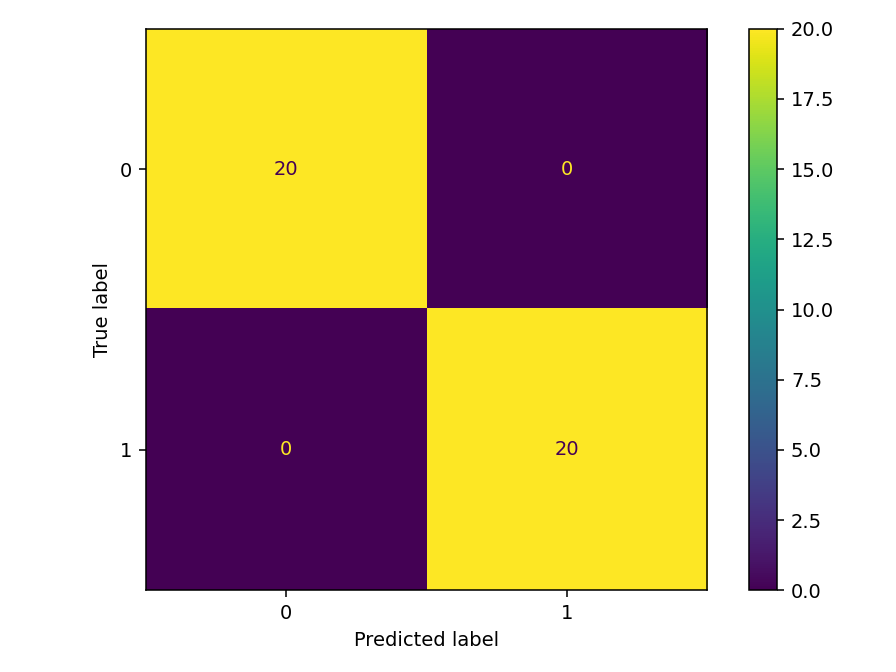

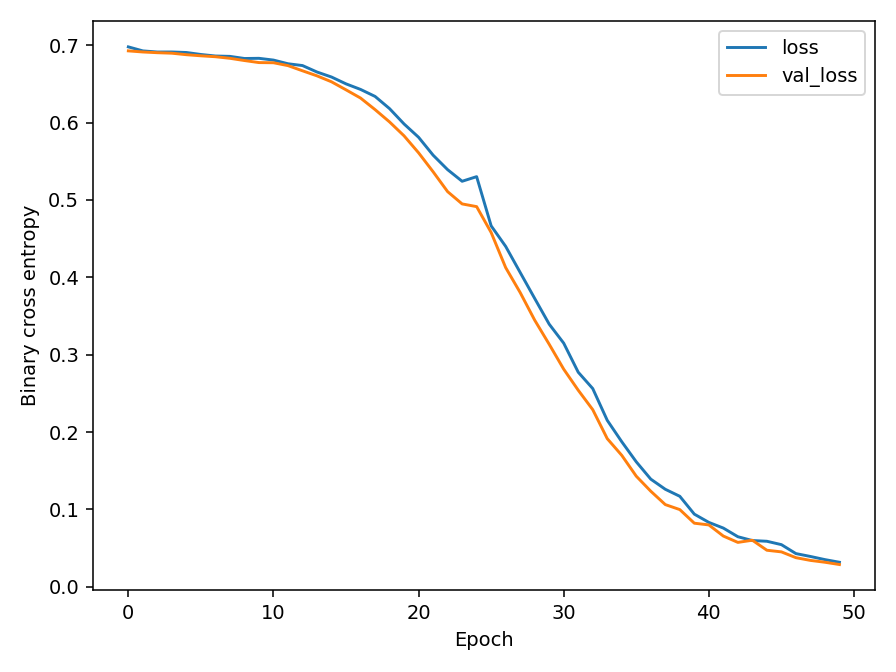

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
